# fedOPD - the federated forecaster

Roadmap step 3. Forecast `demand` 12 months ahead per trust x department, training across the 126
trusts **without pooling their data**, and score on exactly the series and split fixed by
`05_baselines.ipynb`.

Reads `data/canonical/rtt_panel.parquet` and `data/canonical/series_index.csv`. Writes
`data/canonical/fl_results.csv` and `data/canonical/fl_history.csv`.

## What federated means here, concretely

Each of the 126 trusts is a **silo**. A trust's monthly counts never leave it. What leaves is a set of
model weights, once per round. The server averages the weights it receives and sends the average back.
That is FedAvg, and it is implemented directly below rather than through `flwr`, because a hundred
lines of plain torch is auditable and the framework is not the research question. `flwr` is the
deployment path on the A100 box, not a dependency of the result.

## Four models, because a federated number alone means nothing

| | trained on | what it bounds |
|---|---|---|
| `local` | one trust's own data only | what a trust could do alone. The **floor** |
| `fedavg` | all trusts, weights averaged | the actual proposal |
| `fedavg_ft` | fedavg, then fine-tuned locally | personalisation on top of the shared model |
| `central` | everyone's data pooled in one place | the **ceiling**. What federation gives up |

Reporting `fedavg` without `central` hides the cost of federating, and without `local` hides whether
federating bought anything at all. Both are computed.

## The decisions, stated before the numbers

**Temporal split, inherited.** The split month comes from `series_index.csv`. No training window is
allowed to touch a test month - a window straddling the split is how a model gets to see its own test
data while the code still looks correct.

**Per-series scaling, computed locally.** Each series is divided by the mean of its own *training*
months. A global scaler would require pooling the very statistics federation exists to keep local.
Scaling per series rather than per trust is deliberate: within one trust, ophthalmology can be a
hundred times larger than neurosurgery, and a per-trust scaler would let the large department set the
loss for the small ones.

**COVID stays in the training window.** Apr 2020 is a real collapse in referrals. It is in training,
never in test.

**Weighting is reported, not assumed.** FedAvg weights each client's update by its sample count by
default. That gives the largest trusts the most influence over the shared model. The uniform-weight
alternative is run as well and both are reported, because the choice changes whose data the model
serves.

In [1]:
import numpy as np                     # arrays, windowing, and the metrics
import pandas as pd                    # reads the panel and the fixed evaluation set
import torch                           # the model, the optimiser, and the weight arithmetic of FedAvg
import torch.nn as nn                  # nn.Module, nn.Linear: the layer types the model is built from
import matplotlib.pyplot as plt        # the convergence curves
from pathlib import Path

torch.manual_seed(0)                   # every result below is reproducible from this seed. All the
                                       # randomness here is torch's - shuffling and weight init

CANON = Path("../data/canonical")
panel = pd.read_parquet(CANON / "rtt_panel.parquet")
index = pd.read_csv(CANON / "series_index.csv", parse_dates=["split_month"])   # fixed by 05

SPLIT = index.split_month.iloc[0]      # the train/test boundary, inherited not re-chosen
H = int(index.horizon.iloc[0])         # forecast horizon, 12 months
L = 24                                 # lookback: two years in, so an annual cycle is visible twice

# no CUDA on this laptop; on the A100 box this picks up the single MIG slice as an ordinary cuda:0
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"device {device} | split {SPLIT:%Y-%m} | lookback {L} -> horizon {H}")
print(f"evaluation set: {len(index):,} series across {index.provider_code.nunique()} trusts")

device cuda | split 2024-04 | lookback 24 -> horizon 12
evaluation set: 2,085 series across 141 trusts


## 1. Build the client datasets

One tensor pair per trust. A training sample is `L` consecutive months in, the next `H` months out,
with **every one of those L+H months strictly before the split**. The test sample is the last `L`
training months in, the `H` test months out - one per series, which is the same single forecast origin
`05_baselines.ipynb` scored, so the two are directly comparable.

In [2]:
wide = panel.pivot(index=["provider_code", "dept"], columns="month", values="demand")
wide = wide.loc[list(zip(index.provider_code, index.dept))]        # exactly 05's series, in its order
wide.columns = pd.to_datetime(wide.columns)

hist = wide.loc[:, wide.columns < SPLIT].to_numpy(dtype=np.float32)   # training months
# EXACTLY the H months of the scored window. `columns >= SPLIT` would sweep in the sealed test
# year sitting after the validation year, which is the leak 05 seals against.
scored = (wide.columns >= SPLIT) & (wide.columns < SPLIT + pd.DateOffset(months=H))
future = wide.loc[:, scored].to_numpy(dtype=np.float32)
assert future.shape[1] == H, f"scored window is {future.shape[1]} months, expected {H}"
scale = index.mase_scale.to_numpy()                                # 05's MASE denominator, reused
trusts = index.provider_code.to_numpy()

# per-series scaler from TRAINING months only. +1 so a series that is all zeros cannot divide by zero.
norm = hist.mean(axis=1) + 1.0

# Calendar features. Without these the network sees 24 numbers with no idea which calendar months they
# are, because training windows start in every month of the year. Referrals have a strong annual shape
# - August and December are low - so a month-of-year one-hot is the difference between the network
# being able to learn seasonality and having to guess it from position. 12 extra inputs, one per month.
month_ix = np.array([m.month - 1 for m in wide.columns[wide.columns < SPLIT]])   # 0..11 per column
eye = np.eye(12, dtype=np.float32)                                 # one-hot lookup table

clients = {}                                                       # trust code -> (X, Y, row ids)
for code in np.unique(trusts):
    rows = np.flatnonzero(trusts == code)                          # this trust's series
    xs, ys = [], []
    for r in rows:
        s = hist[r] / norm[r]                                      # scaled locally, never globally
        # every window that fits entirely inside the training months - none may touch the split
        for t in range(len(s) - L - H + 1):
            origin = month_ix[t + L - 1]                           # calendar month the forecast starts from
            xs.append(np.concatenate([s[t:t + L], eye[origin]]))
            ys.append(s[t + L:t + L + H])
    clients[code] = (torch.tensor(np.array(xs)), torch.tensor(np.array(ys)), rows)

sizes = {c: len(v[0]) for c, v in clients.items()}
print(f"clients {len(clients)} | training windows {sum(sizes.values()):,}")
print(f"  windows per client: min {min(sizes.values())}, median "
      f"{int(np.median(list(sizes.values())))}, max {max(sizes.values())}")

# the test input: the last L training months of each series, scaled the same way, with the calendar
# month of the forecast origin appended exactly as in training
X_test = torch.tensor(np.concatenate(
    [hist[:, -L:] / norm[:, None],
     np.repeat(eye[month_ix[-1]][None, :], len(hist), axis=0)], axis=1))
IN_DIM = X_test.shape[1]                                           # L lags + 12 calendar features
print(f"test samples: {len(X_test):,} - one forecast origin per series, matching 05")
print(f"input dimension: {IN_DIM} = {L} lags + 12 month-of-year features")

clients 141 | training windows 77,145
  windows per client: min 37, median 629, max 703
test samples: 2,085 - one forecast origin per series, matching 05
input dimension: 36 = 24 lags + 12 month-of-year features


## 2. The model

A feed-forward neural network: `L + 12` inputs, two hidden layers of 128 units with ReLU, dropout on
the first, and `H` outputs. **Direct multi-horizon** - all 12 months come out in one shot rather than
by feeding each prediction back in as the next input, which is what stops errors compounding step by
step over the year.

The 12 extra inputs are the month-of-year one-hot built above. Without them the network gets 24
unlabelled numbers and cannot tell January from July, so it has to infer the annual cycle from position
alone - and training windows start in every month, so position tells it nothing. Given how strong the
seasonal shape is in referrals, that feature is doing more work than the depth is.

Still deliberately modest. The comparison being made is `local` against `fedavg` against `central`, and
a model large enough that only the pooled run can fit it would turn that into a comparison of who had
enough data. A recurrent or attention model belongs on the A100 box once the federated result stands.

In [3]:
HIDDEN = 128                                           # units per hidden layer

def new_model():
    # A feed-forward neural network: two hidden layers with ReLU between them, and dropout, which
    # zeroes a random 10% of units each training step so the network cannot lean on any single one.
    # nn.Sequential simply runs its layers in order.
    return nn.Sequential(
        nn.Linear(IN_DIM, HIDDEN), nn.ReLU(), nn.Dropout(0.1),
        nn.Linear(HIDDEN, HIDDEN), nn.ReLU(),
        nn.Linear(HIDDEN, H)).to(device)

def get_weights(m):
    # model parameters as plain tensors - this is the object a client sends to the server
    return [p.detach().clone() for p in m.parameters()]

def set_weights(m, w):
    # load a weight list back into a model, in place
    with torch.no_grad():                              # no gradient tracking: this is assignment
        for p, q in zip(m.parameters(), w):
            p.copy_(q)

def train_local(model, X, Y, epochs, lr=1e-3):
    # ordinary supervised training on one client's data; returns the last epoch's mean loss
    model.train()                                      # train mode: dropout is active
    opt = torch.optim.Adam(model.parameters(), lr=lr)  # Adam: adaptive per-parameter step sizes
    loss_fn = nn.L1Loss()                              # mean absolute error, matching how we score
    X, Y = X.to(device), Y.to(device)
    for _ in range(epochs):
        perm = torch.randperm(len(X))                  # shuffle each epoch
        total = 0.0
        for i in range(0, len(X), 256):                # minibatches of 256 windows
            b = perm[i:i + 256]
            opt.zero_grad()                            # clear last step's gradients
            loss = loss_fn(model(X[b]), Y[b])
            loss.backward()                            # backpropagate
            opt.step()                                 # update the weights
            total += loss.item() * len(b)
    return total / len(X)

print(f"model: {IN_DIM} -> {HIDDEN} -> {HIDDEN} -> {H}, "
      f"{sum(p.numel() for p in new_model().parameters()):,} parameters")
print("L1 loss, because the metric is MAE. Training on squared error and scoring on absolute error")
print("optimises for a different thing and lets the largest months dominate the gradient.")

model: 36 -> 128 -> 128 -> 12, 22,796 parameters
L1 loss, because the metric is MAE. Training on squared error and scoring on absolute error
optimises for a different thing and lets the largest months dominate the gradient.


## 3. Scoring

Predictions come back in scaled units and are multiplied by each series' own scaler to become
referrals again. MASE uses the denominator `05_baselines.ipynb` computed on the training portion, so
the number here and the number there mean the same thing.

In [4]:
def predict(model):
    # one forward pass over the test inputs, returned in scaled units
    model.eval()                                       # eval mode: dropout off
    with torch.no_grad():                              # a forward pass needs no gradients
        return model(X_test.to(device)).cpu().numpy()

def evaluate(scaled):
    # scaled predictions -> referrals, then MAE and MASE per series
    pred = np.clip(scaled * norm[:, None], 0, None)    # negatives are not forecasts
    mae = np.abs(pred - future).mean(axis=1)
    mase = np.where(scale > 0, mae / np.where(scale > 0, scale, 1), np.nan)
    return pred, mae, mase

# SS_tot for the two R squareds, defined exactly as in 05 so the tables can sit next to each other
SS_POOLED = ((future - future.mean()) ** 2).sum()                  # one grand mean over everything
SS_WITHIN = ((future - future.mean(axis=1, keepdims=True)) ** 2).sum(axis=1)   # each series' own mean

def summarise(name, pred, mae, mase):
    # every metric for one model, on the same definitions 05 used
    err = pred - future
    rmse = np.sqrt((err ** 2).mean(axis=1))
    ss_res = (err ** 2).sum(axis=1)
    r2_within = np.where(SS_WITHIN > 0, 1 - ss_res / np.where(SS_WITHIN > 0, SS_WITHIN, 1), np.nan)
    return {"model": name,
            "MAE_mean": mae.mean(), "MAE_median": np.median(mae),
            "RMSE_mean": rmse.mean(), "RMSE_median": np.median(rmse),
            "RMSE_pooled": np.sqrt((err ** 2).mean()),
            "MASE_mean": np.nanmean(mase), "MASE_median": np.nanmedian(mase),
            "R2_pooled": 1 - ss_res.sum() / SS_POOLED,            # flattered by between-series variance
            "R2_within_median": np.nanmedian(r2_within)}          # the honest one

baselines = pd.read_csv(CANON / "baselines.csv", index_col=0)      # the bar from 05
BAR = baselines.MASE_median.min()
print(f"the bar to clear: median MASE {BAR:.3f} ({baselines.MASE_median.idxmin()})")

the bar to clear: median MASE 0.510 (naive)


## 4. Central - the ceiling

Every client's windows pooled into one training set. This is what the data could support if privacy
were not a constraint, and it is the number `fedavg` is measured against. It is not a deployable
model; it exists to price the federation.

In [5]:
X_all = torch.cat([v[0] for v in clients.values()])    # every window from every client, pooled
Y_all = torch.cat([v[1] for v in clients.values()])
print(f"pooled training set: {len(X_all):,} windows")

central = new_model()
for e in range(20):                                    # 20 passes over the pooled data
    loss = train_local(central, X_all, Y_all, epochs=1)
    if (e + 1) % 5 == 0:
        print(f"  epoch {e + 1:2d}  train L1 {loss:.4f}")

pred_c, mae_c, mase_c = evaluate(predict(central))
res = [summarise("central", pred_c, mae_c, mase_c)]
print(f"\ncentral: median MASE {np.nanmedian(mase_c):.3f}")

pooled training set: 77,145 windows


  epoch  5  train L1 0.1969


  epoch 10  train L1 0.1911


  epoch 15  train L1 0.1877


  epoch 20  train L1 0.1853

central: median MASE 0.665


## 5. Local - the floor

Each trust fits its own model on its own windows and nothing is shared. This is the honest alternative
to federating, and if `fedavg` cannot beat it then the federation is adding coordination cost for
nothing.

In [6]:
local_pred = np.zeros_like(future)                     # filled trust by trust
for code, (X, Y, rows) in clients.items():
    m = new_model()
    train_local(m, X, Y, epochs=20)                    # same budget as central, on far less data
    m.eval()
    with torch.no_grad():
        local_pred[rows] = m(X_test[rows].to(device)).cpu().numpy()

pred_l, mae_l, mase_l = evaluate(local_pred)
res.append(summarise("local", pred_l, mae_l, mase_l))
print(f"local: median MASE {np.nanmedian(mase_l):.3f}")
print(f"trusts trained: {len(clients)}, each on {int(np.median(list(sizes.values())))} windows "
      f"(median) against the pooled {len(X_all):,}")

local: median MASE 0.556
trusts trained: 141, each on 629 windows (median) against the pooled 77,145


## 6. FedAvg

One round is: the server sends the current weights to every selected client; each client trains for
`E` local epochs on its own data; each returns its weights; the server averages them.

The averaging weight is the decision worth arguing about. `n` weights each client by its window count,
which is standard FedAvg and gives the biggest trusts the most say. `uniform` gives every trust an
equal vote regardless of size. Both are run, because on this data the trusts differ in size by two
orders of magnitude and the choice is a policy question, not a hyperparameter.

In [7]:
ROUNDS, LOCAL_EPOCHS = 30, 2                           # 30 server rounds, 2 local epochs each

def fedavg(weighting):
    # run FedAvg to convergence; weighting is 'n' (by sample count) or 'uniform'
    codes = list(clients)
    w = get_weights(new_model())                       # the shared starting point
    if weighting == "n":
        alpha = np.array([sizes[c] for c in codes], dtype=float)   # by window count
    else:
        alpha = np.ones(len(codes))                    # one trust, one vote
    alpha = alpha / alpha.sum()                        # must sum to 1 or the average rescales the model

    model = new_model()
    history = []
    for r in range(ROUNDS):
        acc = [torch.zeros_like(p) for p in w]         # the running weighted sum of client weights
        for a, c in zip(alpha, codes):
            set_weights(model, w)                      # every client starts the round from the server's model
            train_local(model, clients[c][0], clients[c][1], epochs=LOCAL_EPOCHS)
            for s, p in zip(acc, get_weights(model)):
                s += a * p                             # accumulate this client's contribution
        w = acc                                        # the new global model
        set_weights(model, w)
        _, _, mase = evaluate(predict(model))
        history.append({"round": r + 1, "weighting": weighting, "MASE_median": np.nanmedian(mase)})
        if (r + 1) % 5 == 0:
            print(f"  round {r + 1:2d}  median MASE {history[-1]['MASE_median']:.3f}")
    return model, pd.DataFrame(history)

print("FedAvg, weighted by client sample count:")
fed_n, hist_n = fedavg("n")
print("\nFedAvg, uniform client weights:")
fed_u, hist_u = fedavg("uniform")

preds = {}
for name, m in [("fedavg_n", fed_n), ("fedavg_uniform", fed_u)]:
    pr, mae, mase = evaluate(predict(m))
    preds[name] = pr
    res.append(summarise(name, pr, mae, mase))
    print(f"{name}: median MASE {np.nanmedian(mase):.3f}")

FedAvg, weighted by client sample count:


  round  5  median MASE 0.565


  round 10  median MASE 0.529


  round 15  median MASE 0.522


  round 20  median MASE 0.538


  round 25  median MASE 0.544


... (3 outputs left out)

  round 15  median MASE 0.524


  round 20  median MASE 0.531


  round 25  median MASE 0.545


  round 30  median MASE 0.565
fedavg_n: median MASE 0.553
fedavg_uniform: median MASE 0.565


## 7. Per-client fine-tuning

The shared model is one model for 126 trusts with very different case mixes. Fine-tuning starts each
trust from the shared weights and takes a few local steps, which keeps what the federation learned and
adapts the last of it locally. If this beats both `fedavg` and `local`, the shared model is carrying
information a trust could not have learned alone - which is the claim the whole design rests on.

In [8]:
FT_EPOCHS = 5                                          # a short local adaptation, not a retrain

shared = get_weights(fed_n)                            # start every trust from the sample-weighted model
ft_pred = np.zeros_like(future)
for code, (X, Y, rows) in clients.items():
    m = new_model()
    set_weights(m, shared)
    train_local(m, X, Y, epochs=FT_EPOCHS, lr=3e-4)    # lower lr: adapt, do not overwrite
    m.eval()
    with torch.no_grad():
        ft_pred[rows] = m(X_test[rows].to(device)).cpu().numpy()

pred_ft, mae_ft, mase_ft = evaluate(ft_pred)
res.append(summarise("fedavg_ft", pred_ft, mae_ft, mase_ft))
print(f"fedavg_ft: median MASE {np.nanmedian(mase_ft):.3f}")

# Does fine-tuning help every trust, or only on average? A mean can hide half the fleet getting worse,
# and a system that improves the fleet by damaging a third of it is not deployable.
_, _, mase_fed = evaluate(predict(fed_n))   # per-series MASE of the shared model, for the comparison below
per_trust = (pd.DataFrame({"trust": trusts, "fedavg": mase_fed, "finetuned": mase_ft})
               .groupby("trust").median())
better = (per_trust.finetuned < per_trust.fedavg).mean() * 100
print(f"trusts improved by fine-tuning: {better:.0f}% of {len(per_trust)}")
print(f"trusts made worse             : {100 - better:.0f}%")

fedavg_ft: median MASE 0.568
trusts improved by fine-tuning: 45% of 141
trusts made worse             : 55%


## 8. The comparison

Everything on one table, against the baselines from `05`. The question is not whether the network
trained - it is whether it beat a calendar.

In [9]:
results = pd.DataFrame(res).set_index("model")
table = pd.concat([baselines.reindex(columns=results.columns), results])   # same columns both halves
print(table.round(3).to_string())
print()

winner = table.MASE_median.idxmin()
print(f"best on median MASE: {winner} ({table.MASE_median.min():.3f})")
print(f"the baseline bar was {BAR:.3f} ({baselines.MASE_median.idxmin()})")
if table.MASE_median.min() >= BAR:
    print("\nNO MODEL BEAT THE BASELINE. That is a result, not a failure of the run, and it is what")
    print("gets reported. The next question is which assumption is wrong: the horizon, the lookback,")
    print("the architecture, or the premise that cross-trust sharing helps at all.")
else:
    print(f"\nfederation vs going it alone : {results.loc['local', 'MASE_median']:.3f} local -> "
          f"{results.loc['fedavg_n', 'MASE_median']:.3f} fedavg")
    print(f"cost of federating            : {results.loc['central', 'MASE_median']:.3f} central "
          f"(pooled ceiling) vs {results.loc['fedavg_n', 'MASE_median']:.3f} fedavg")

results.to_csv(CANON / "fl_results.csv")
pd.concat([hist_n, hist_u]).to_csv(CANON / "fl_history.csv", index=False)   # not `hist`: that is the data
print(f"\nwritten: fl_results.csv, fl_history.csv")

                MAE_mean  MAE_median  RMSE_mean  RMSE_median  RMSE_pooled  MASE_mean  MASE_median  R2_pooled  R2_within_median
naive             92.618      59.667    111.382       72.778      186.731      0.692        0.510      0.968            -0.667
seasonal_naive   111.997      71.500    136.633       87.266      234.267      0.813        0.617      0.949            -1.488
mean12            96.112      59.208    114.493       72.165      192.331      0.710        0.512      0.966            -0.492
drift            122.828      73.023    145.016       88.336      262.002      0.911        0.641      0.936            -1.451
central          125.188      78.628    148.990       96.087      245.742      0.855        0.665      0.944            -1.858
local            105.328      63.573    124.567       77.099      221.663      0.747        0.556      0.954            -0.786
fedavg_n         101.799      62.551    119.566       74.724      195.240      0.738        0.553      0.964   

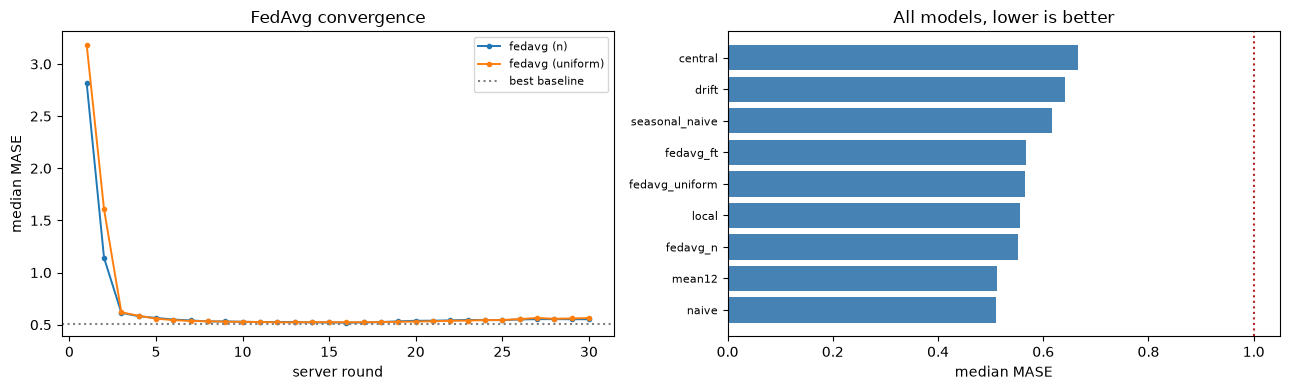

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

for w, h in [("n", hist_n), ("uniform", hist_u)]:      # does the weighting change convergence?
    ax[0].plot(h["round"], h.MASE_median, lw=1.4, marker="o", ms=3, label=f"fedavg ({w})")
ax[0].axhline(BAR, color="grey", ls=":", label="best baseline")
ax[0].set_xlabel("server round"); ax[0].set_ylabel("median MASE")
ax[0].set_title("FedAvg convergence"); ax[0].legend(fontsize=8)

order = table.MASE_median.sort_values()                # every model and baseline, ranked
ax[1].barh(range(len(order)), order.to_numpy(), color="steelblue")
ax[1].set_yticks(range(len(order))); ax[1].set_yticklabels(order.index, fontsize=8)
ax[1].axvline(1.0, color="firebrick", ls=":")          # MASE 1 = no better than last year
ax[1].set_xlabel("median MASE"); ax[1].set_title("All models, lower is better")
plt.tight_layout()

## 9. Evaluation

The table above is the summary; this is the diagnosis. Six views of the winning model against the
seasonal-naive baseline, because a model can win on median MASE while being useless in the ways that
matter - biased in one direction, accurate only at short horizons, or carried by a handful of large
trusts while most services get worse.

Read the R squared pair carefully. `R2_pooled` will look strong, and almost all of what it measures is
the model knowing that Manchester is larger than Moorfields. `R2_within_median` is the one that says
whether the year's shape was predicted for a typical service, and it is normal for it to be far lower
and entirely possible for it to be negative.

naive vs seasonal-naive, per service: 59.5% improved, 40.5% made worse
pooled RMSE 186.7 referrals | R2_pooled 0.968 | R2_within median -0.667
fraction of services with within-series R2 above 0: 9.3% - i.e. beaten a flat line at their own mean

A high pooled R2 next to a low within-series R2 is the signature of a model that has learned
the size of each service and little about its dynamics. Both numbers are reported for that
reason; either alone would be misleading.


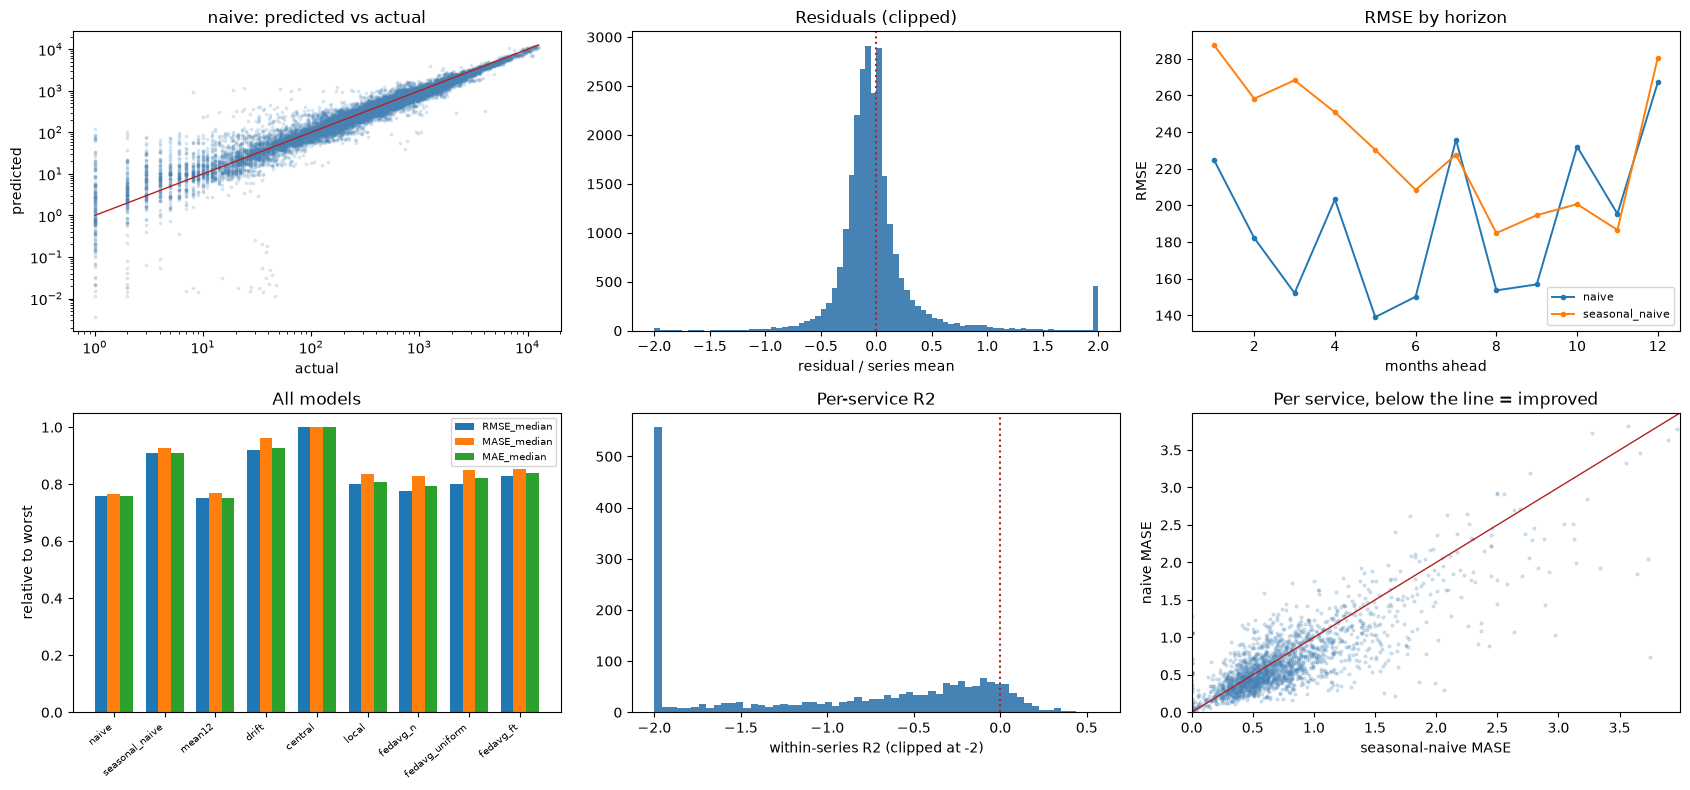

In [11]:
BEST = table.MASE_median.idxmin()                      # the model to diagnose
best_pred = {"central": pred_c, "local": pred_l, "fedavg_ft": pred_ft, **preds}.get(BEST, preds["fedavg_n"])
snaive = hist[:, -12:][:, np.arange(H) % 12]           # last year repeated forward, the 05 baseline

fig, ax = plt.subplots(2, 3, figsize=(17, 8))

# 1. predicted vs actual, log-log: series sizes span four orders of magnitude
a, p = future.ravel(), best_pred.ravel()
keep = (a > 0) & (p > 0)
ax[0, 0].scatter(a[keep], p[keep], s=3, alpha=0.15, color="steelblue")
lim = [max(1, a[keep].min()), a.max()]
ax[0, 0].plot(lim, lim, color="firebrick", lw=1)       # the diagonal
ax[0, 0].set_xscale("log"); ax[0, 0].set_yscale("log")
ax[0, 0].set_xlabel("actual"); ax[0, 0].set_ylabel("predicted"); ax[0, 0].set_title(f"{BEST}: predicted vs actual")

# 2. residuals scaled by each series' own mean, so large and small series are comparable
resid = (best_pred - future) / (future.mean(axis=1, keepdims=True) + 1)
ax[0, 1].hist(np.clip(resid.ravel(), -2, 2), bins=80, color="steelblue")
ax[0, 1].axvline(0, color="firebrick", ls=":")
ax[0, 1].set_xlabel("residual / series mean"); ax[0, 1].set_title("Residuals (clipped)")

# 3. RMSE by horizon: what limits how far ahead the decision layer can plan
for name, pr in [(BEST, best_pred), ("seasonal_naive", snaive)]:
    ax[0, 2].plot(range(1, H + 1), np.sqrt(((pr - future) ** 2).mean(axis=0)),
                  lw=1.4, marker="o", ms=3, label=name)
ax[0, 2].set_xlabel("months ahead"); ax[0, 2].set_ylabel("RMSE")
ax[0, 2].set_title("RMSE by horizon"); ax[0, 2].legend(fontsize=8)

# 4. every model on the three headline metrics, each scaled to its own worst value so they share an axis
show = table[["RMSE_median", "MASE_median", "MAE_median"]]
xs = np.arange(len(show))
for i, c in enumerate(show.columns):
    ax[1, 0].bar(xs + i * 0.25, show[c] / show[c].max(), width=0.25, label=c)
ax[1, 0].set_xticks(xs + 0.25); ax[1, 0].set_xticklabels(show.index, rotation=40, ha="right", fontsize=7)
ax[1, 0].set_ylabel("relative to worst"); ax[1, 0].legend(fontsize=7); ax[1, 0].set_title("All models")

# 5. the within-series R squared distribution: how many services are genuinely tracked
ss_res = ((best_pred - future) ** 2).sum(axis=1)
r2w = np.where(SS_WITHIN > 0, 1 - ss_res / np.where(SS_WITHIN > 0, SS_WITHIN, 1), np.nan)
ax[1, 1].hist(np.clip(r2w[np.isfinite(r2w)], -2, 1), bins=60, color="steelblue")
ax[1, 1].axvline(0, color="firebrick", ls=":")         # 0 = no better than a flat line at the series mean
ax[1, 1].set_xlabel("within-series R2 (clipped at -2)"); ax[1, 1].set_title("Per-service R2")

# 6. per-series MASE, model against baseline. Points below the diagonal are services the model helped.
base_mase = np.abs(snaive - future).mean(axis=1) / np.where(scale > 0, scale, np.nan)
best_mase = np.abs(best_pred - future).mean(axis=1) / np.where(scale > 0, scale, np.nan)
ax[1, 2].scatter(base_mase, best_mase, s=4, alpha=0.2, color="steelblue")
mx = np.nanpercentile(base_mase, 99)
ax[1, 2].plot([0, mx], [0, mx], color="firebrick", lw=1)
ax[1, 2].set_xlim(0, mx); ax[1, 2].set_ylim(0, mx)
ax[1, 2].set_xlabel("seasonal-naive MASE"); ax[1, 2].set_ylabel(f"{BEST} MASE")
ax[1, 2].set_title("Per service, below the line = improved")
plt.tight_layout()

helped = np.nanmean(best_mase < base_mase) * 100
print(f"{BEST} vs seasonal-naive, per service: {helped:.1f}% improved, {100 - helped:.1f}% made worse")
print(f"pooled RMSE {table.loc[BEST, 'RMSE_pooled']:,.1f} referrals | "
      f"R2_pooled {table.loc[BEST, 'R2_pooled']:.3f} | "
      f"R2_within median {table.loc[BEST, 'R2_within_median']:.3f}")
print(f"fraction of services with within-series R2 above 0: "
      f"{np.nanmean(r2w > 0) * 100:.1f}% - i.e. beaten a flat line at their own mean")
print()
print("A high pooled R2 next to a low within-series R2 is the signature of a model that has learned")
print("the size of each service and little about its dynamics. Both numbers are reported for that")
print("reason; either alone would be misleading.")

## 10. The call the board actually receives — up, flat or down

MASE is not what a planner reads. The question that reaches the board is: **is this service heading up,
staying flat, or heading down over the planning horizon — and how often is that call right?**

That last clause is the point. A direction with no reliability attached is not decision support; a
board needs to know that when the system says "growing", it is right *P%* of the time, because *P* is
what determines whether they commit capacity on it. **Per-class precision is that number** and it is
reported here for every model, including the post-training one (`fedavg_ft` — FedAvg then fine-tuned
locally).

Three classes on the same definition `05` used, so the neural models and the baselines are directly
comparable: growth over the horizon relative to the last 12 training months, split at ±5%.

Predictions are also written to `fl_predictions.csv`, so any later analysis of this run does not need
an hour of retraining to ask a new question of it.

In [12]:
BAND = 0.05                                            # +/-5%: outside is up or down, inside is flat
ref = hist[:, -12:].mean(axis=1)                       # last 12 training months, the reference level

def growth_of(pred):
    # a forecast's implied growth over the horizon, against the same reference level
    return pred.mean(axis=1) / np.where(ref > 0, ref, np.nan) - 1

def label(g):
    # -1 down, 0 flat, +1 up
    return np.where(g > BAND, 1, np.where(g < -BAND, -1, 0))

truth = label(growth_of(future))
valid = np.isfinite(growth_of(future))
names = ["down", "flat", "up"]
print(f"services scored: {int(valid.sum()):,}")
for k, n in zip((-1, 0, 1), names):
    print(f"  actually {n:5s}: {int((truth[valid] == k).sum()):5,d}  ({(truth[valid] == k).mean() * 100:4.1f}%)")
majority = max((truth[valid] == k).mean() for k in (-1, 0, 1)) * 100
print(f"always calling the commonest class: {majority:.1f}% accuracy - the only line to read accuracy against")


services scored: 1,978
  actually down :   510  (25.8%)
  actually flat :   560  (28.3%)
  actually up   :   908  (45.9%)
always calling the commonest class: 45.9% accuracy - the only line to read accuracy against


In [13]:
all_preds = {"central": pred_c, "local": pred_l, "fedavg_ft": pred_ft, **preds}
rows = []
for name, pr in all_preds.items():
    call = label(growth_of(pr))
    ok = valid & np.isfinite(growth_of(pr))
    r = {"model": name, "accuracy_pct": (call[ok] == truth[ok]).mean() * 100}
    for k, n in zip((-1, 0, 1), names):
        said = call[ok] == k
        # precision: when this model says `n`, how often is it right. This is the number a board needs.
        r[f"precision_{n}"] = (truth[ok][said] == k).mean() * 100 if said.sum() else np.nan
        r[f"n_said_{n}"] = int(said.sum())
    rows.append(r)

direction = pd.DataFrame(rows).set_index("model").sort_values("accuracy_pct", ascending=False)
print(direction.round(1).to_string())
print()
print(f"majority-class accuracy is {majority:.1f}%. A model below that line is worse than a constant.")
print("`n_said_up` near zero means the model never calls growth - it cannot trigger an expansion")
print("decision no matter how good its MASE looks. That is the failure mode 05 found in mean12.")

direction.to_csv(CANON / "direction_calls.csv")

# keep every model's per-service forecast, so a new question does not cost another training run
out = pd.DataFrame({"provider_code": index.provider_code, "dept": index.dept,
                    "actual_growth": growth_of(future), "actual_class": truth})
for name, pr in all_preds.items():
    out[f"{name}_growth"] = growth_of(pr)
    out[f"{name}_class"] = label(growth_of(pr))
out.to_csv(CANON / "fl_predictions.csv", index=False)
print(f"\nwritten: direction_calls.csv, fl_predictions.csv ({len(out):,} services)")


                accuracy_pct  precision_down  n_said_down  precision_flat  n_said_flat  precision_up  n_said_up
model                                                                                                          
local                   38.6            35.6          497            32.1         1011          55.5        470
fedavg_n                38.0            35.7          898            29.4          763          65.0        317
fedavg_uniform          37.5            35.3          941            29.2          754          67.1        283
central                 36.1            32.9         1178            28.0          536          67.4        264
fedavg_ft               35.8            33.8          974            27.6          744          67.3        260

majority-class accuracy is 45.9%. A model below that line is worse than a constant.
`n_said_up` near zero means the model never calls growth - it cannot trigger an expansion
decision no matter how good its MASE look

## What this does not show

- **One split, one seed.** Every number is a single held-out year. The seed is fixed so the run
  reproduces, but a single origin does not establish that the ranking is stable, and it should be
  re-run across several split points before being quoted.
- **No privacy mechanism.** FedAvg moves weights instead of rows, which is a data-governance property,
  not a privacy guarantee. Weights leak information about the data that produced them. Differential
  privacy or secure aggregation is a separate piece of work and is not implemented here.
- **Sequential simulation.** All 126 clients run in one process, one after another. On the A100 box
  the MIG constraint forces the same thing: a single instance cannot do peer-to-peer collectives, so
  clients run sequentially there too. Nothing here measures real communication cost.
- **`X_OTHER` spans a known break.** The Feb-2024 community-services removal sits inside the training
  window for that series and is not corrected. Any `X_OTHER` result should be read with that in mind.